In [ ]:

# Imports
import os
import torch
import numpy as np
import torch.nn as nn
import torchaudio 
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import average_precision_score

from BEATs import BEATs, BEATsConfig

# Dataset Class
class AudioDataset(Dataset):
    def __init__(self, root_fol, target_sr=16000):
        self.file_paths = []
        self.labels = []

        self.CLASS_MAP = {
            "Gunshot": 0,
            "Human": 1,
            "Vehicle": 2
        }

        for class_name, label in self.CLASS_MAP.items():
            class_path = os.path.join(root_fol, class_name)

            if not os.path.isdir(class_path):
                print(f"WARNING: Missing folder {class_path}")
                continue

            for file in os.listdir(class_path):
                if file.endswith(".wav"):
                    full_path = os.path.join(class_path, file)

                    # Skip broken/empty files
                    try:
                        waveform, sr = torchaudio.load(full_path)
                        if waveform.numel() == 0:
                            continue
                    except:
                        continue

                    self.file_paths.append(full_path)
                    self.labels.append(label)

        self.target_sr = target_sr

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):

        MAX_SECONDS = 5 
        MAX_LENGTH = self.target_sr * MAX_SECONDS

        waveform, sr = torchaudio.load(self.file_paths[idx])

        # Convert to mono 
        if waveform.shape[0] > 1:  
            waveform = waveform.mean(dim=0, keepdim=True)

        # Resample
        if sr != self.target_sr:
            resampler = torchaudio.transforms.Resample(sr, self.target_sr)
            waveform = resampler(waveform)

        waveform = waveform.squeeze(0)
        # Trim if too long
        if waveform.shape[0] > MAX_LENGTH:
            waveform = waveform[:MAX_LENGTH]

        # Pad if too short
        elif waveform.shape[0] < MAX_LENGTH:
            pad_len = MAX_LENGTH - waveform.shape[0]
            waveform = torch.nn.functional.pad(waveform, (0, pad_len))
        label = self.labels[idx]

        return waveform, label


# Collate Function Padding
def pad_audio(batch):
    waveforms, labels = zip(*batch)

    lengths = [w.shape[0] for w in waveforms]
    max_len = max(lengths)

    padded = []
    padding_masks = []

    for w in waveforms:
        pad_len = max_len - w.shape[0]
        padded_wave = torch.nn.functional.pad(w, (0, pad_len))
        padded.append(padded_wave)

        mask = torch.zeros(max_len, dtype=torch.bool)
        if pad_len > 0:
            mask[-pad_len:] = True
        padding_masks.append(mask)

    return torch.stack(padded), torch.tensor(labels), torch.stack(padding_masks)


# Load BEATs Pretrained Model
checkpoint = torch.load("BEATs_iter3_plus_AS2M.pt", map_location="cpu")

config = BEATsConfig(checkpoint["cfg"])
audio_model = BEATs(config)
audio_model.load_state_dict(checkpoint["model"])

# Freeze backbone
for param in audio_model.parameters():
    param.requires_grad = False

"""
for name, param in audio_model.named_parameters():
    if "encoder.layers.10" in name or "encoder.layers.11" in name:
        param.requires_grad = True
    else:
        param.requires_grad = False
"""

#  Classifier Model
class BEATsClassifier(nn.Module):
    def __init__(self, beats_model, num_classes):
        super().__init__()
        self.beats = beats_model
        self.classifier = nn.Linear(beats_model.cfg.encoder_embed_dim, num_classes)

    def forward(self, x, padding_mask=None):
        features = self.beats.extract_features(x, padding_mask)[0]
        pooled = features.mean(dim=1)
        logits = self.classifier(pooled)
        return logits


# Data Loaders
train_root = "../esc50/audio/Training"
test_root  = "../esc50/audio/Testing"

train_dataset = AudioDataset(train_root)
test_dataset  = AudioDataset(test_root)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=pad_audio)
test_loader  = DataLoader(test_dataset, batch_size=8, shuffle=False, collate_fn=pad_audio)

num_classes = 3
print("Dataset loaded.")
print(f"Train samples: {len(train_dataset)}")
print(f"Test samples: {len(test_dataset)}")


# Model Setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BEATsClassifier(audio_model, num_classes).to(device)

criterion = nn.CrossEntropyLoss()

# Train only classifier
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=1e-3)


# Training Loop
epochs = 10

for epoch in range(epochs):

    # ---------- Training ----------
    model.train()
    train_loss = 0.0

    for audio, labels, padding_mask in train_loader:
        audio = audio.to(device)
        labels = labels.to(device)
        padding_mask = padding_mask.to(device)

        optimizer.zero_grad()

        outputs = model(audio, padding_mask)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)

    # ---------- Evaluation ----------
    model.eval()
    test_loss = 0.0

    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for audio, labels, padding_mask in test_loader:
            audio = audio.to(device)
            labels = labels.to(device)
            padding_mask = padding_mask.to(device)

            outputs = model(audio, padding_mask)
            loss = criterion(outputs, labels)

            test_loss += loss.item()

            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    avg_test_loss = test_loss / len(test_loader)

    # Accuracy
    accuracy = (np.array(all_preds) == np.array(all_labels)).mean() * 100

    # mAP
    y_true_onehot = np.eye(num_classes)[all_labels]
    y_score = np.array(all_probs)

    ap_per_class = []
    for i in range(num_classes):
        ap = average_precision_score(y_true_onehot[:, i], y_score[:, i])
        ap_per_class.append(ap)

    mAP = np.mean(ap_per_class) * 100

    print(f"Epoch {epoch+1:02d} | "
          f"Train Loss: {avg_train_loss:.4f} | "
          f"Test Loss: {avg_test_loss:.4f} | "
          f"Accuracy: {accuracy:.2f}% | "  
          f"mAP: {mAP:.2f}%")

c:\Users\ASHU\anaconda3\envs\masters_env\lib\site-packages\torch\nn\utils\weight_norm.py:28: UserWarning: torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.
  warnings.warn("torch.nn.utils.weight_norm is deprecated in favor of torch.nn.utils.parametrizations.weight_norm.")


Dataset loaded.
Train samples: 900
Test samples: 300
Epoch 01 | Train Loss: 0.4971 | Test Loss: 0.2681 | Accuracy: 95.67% | mAP: 99.02%
Epoch 02 | Train Loss: 0.1962 | Test Loss: 0.1603 | Accuracy: 96.33% | mAP: 99.48%
Epoch 03 | Train Loss: 0.1192 | Test Loss: 0.1190 | Accuracy: 97.00% | mAP: 99.69%
Epoch 04 | Train Loss: 0.0916 | Test Loss: 0.0911 | Accuracy: 98.67% | mAP: 99.83%
Epoch 05 | Train Loss: 0.0706 | Test Loss: 0.0784 | Accuracy: 98.33% | mAP: 99.87%
Epoch 06 | Train Loss: 0.0586 | Test Loss: 0.0650 | Accuracy: 99.00% | mAP: 99.90%
Epoch 07 | Train Loss: 0.0568 | Test Loss: 0.0557 | Accuracy: 99.00% | mAP: 99.92%
Epoch 08 | Train Loss: 0.0370 | Test Loss: 0.0528 | Accuracy: 99.33% | mAP: 99.91%
Epoch 09 | Train Loss: 0.0378 | Test Loss: 0.0448 | Accuracy: 99.67% | mAP: 99.93%
Epoch 10 | Train Loss: 0.0278 | Test Loss: 0.0427 | Accuracy: 99.33% | mAP: 99.93%


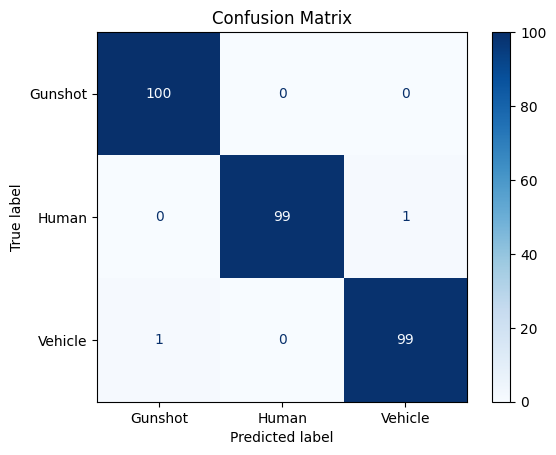

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_names = ["Gunshot", "Human", "Vehicle"]

cm = confusion_matrix(all_labels, all_preds)

disCM = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disCM.plot(cmap="Blues", values_format='d')

plt.title("BEATs Confusion Matrix")
plt.show()